# Capítulo 3 — Onde e quando o atraso acontece

Se o atraso é o principal motivo das notas ruins, o próximo passo é entender **onde** (estado, etapa da entrega)
e **quando** (período) ele se concentra.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

from utils import AZUL, LARANJA, CINZA, TEXTO, TEXTO_2, NORDESTE
from utils import aplicar_estilo, subtitulo, fonte, salvar, carregar_base, apenas_entregues

aplicar_estilo()
base = carregar_base()
entregues = apenas_entregues(base)
print("reviews:", len(base), "| reviews de pedidos entregues:", len(entregues))

reviews: 99224 | reviews de pedidos entregues: 96359


## 3.1 Linha do tempo: a crise de fevereiro e março de 2018

Só entram meses com pelo menos 500 pedidos entregues.

,qtd_pedidos,porcentagem_atrasados,nota_media
mes_compra,,,
2017-01,748,2.81,4.21
2017-02,1651,2.54,4.20
2017-03,2542,4.45,4.18
2017-04,2296,6.45,4.14
2017-05,3553,2.79,4.24
2017-06,3142,2.93,4.22
2017-07,3882,2.76,4.25
2017-08,4207,2.92,4.31
2017-09,4144,4.27,4.27


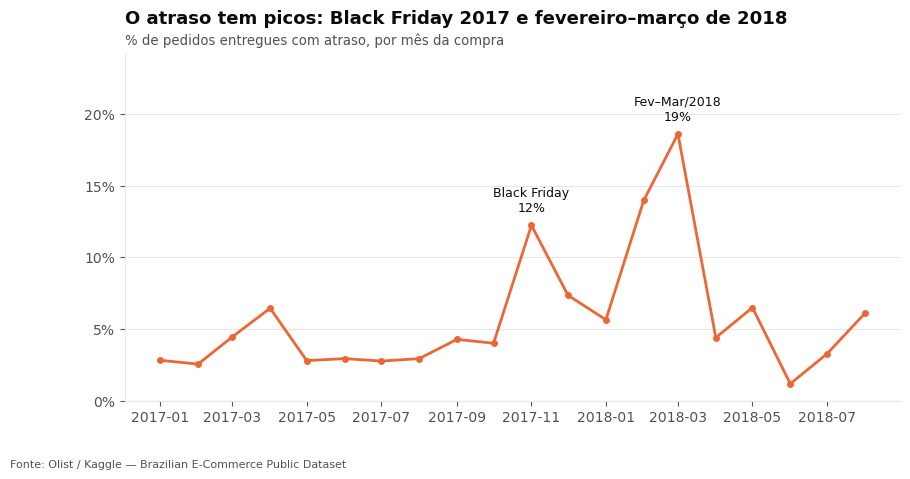

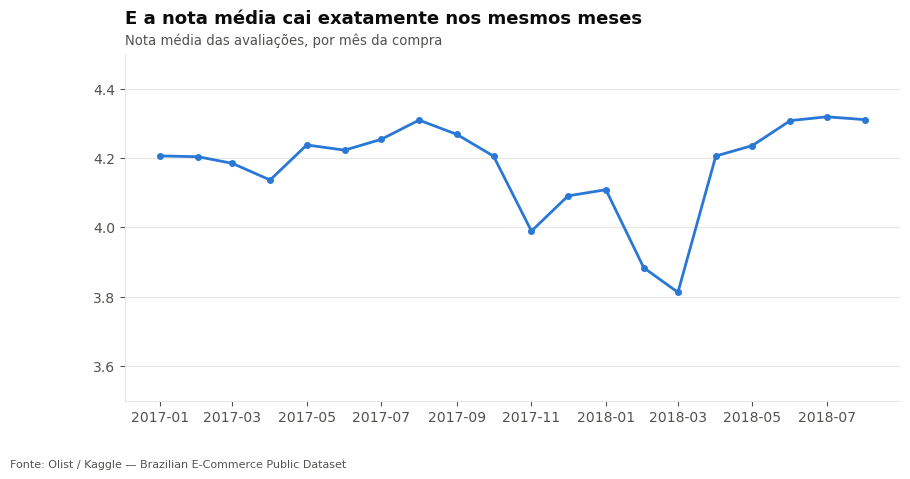

In [2]:
entregues["mes_compra"] = entregues["order_purchase_timestamp"].dt.to_period("M")
por_mes = entregues.groupby("mes_compra").agg(
    qtd_pedidos=("review_id", "count"),
    porcentagem_atrasados=("entrega_atrasada", "mean"),
    nota_media=("review_score", "mean"),
)
por_mes["porcentagem_atrasados"] *= 100
por_mes = por_mes.loc[por_mes["qtd_pedidos"] >= 500]
display(por_mes.round(2))

x = por_mes.index.to_timestamp()
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(x, por_mes["porcentagem_atrasados"], color=LARANJA, linewidth=2, marker="o", markersize=4)
for mes, texto in [("2017-11", "Black Friday"), ("2018-03", "Fev–Mar/2018")]:
    p = pd.Period(mes)
    valor = por_mes.loc[p, "porcentagem_atrasados"]
    ax.annotate(f"{texto}\n{valor:.0f}%", (p.to_timestamp(), valor), textcoords="offset points",
                xytext=(0, 10), ha="center", color=TEXTO, fontsize=9)
ax.set_title("O atraso tem picos: Black Friday 2017 e fevereiro–março de 2018", pad=22)
subtitulo(ax, "% de pedidos entregues com atraso, por mês da compra")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylim(0, por_mes["porcentagem_atrasados"].max() * 1.3)
ax.grid(axis="x", visible=False)
fonte(fig)
salvar(fig, "05_atraso_por_mes")
plt.show()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(x, por_mes["nota_media"], color=AZUL, linewidth=2, marker="o", markersize=4)
ax.set_title("E a nota média cai exatamente nos mesmos meses", pad=22)
subtitulo(ax, "Nota média das avaliações, por mês da compra")
ax.set_ylim(3.5, 4.5)
ax.grid(axis="x", visible=False)
fonte(fig)
salvar(fig, "06_nota_por_mes")
plt.show()

> Observação: nos últimos meses da base (jul–ago/2018) só aparecem pedidos que já tinham sido entregues
> quando os dados foram extraídos, o que tende a favorecer entregas rápidas. Por isso esses meses
> podem estar com atraso subestimado.

## 3.2 Por estado: o Nordeste atrasa muito mais

,qtd_pedidos,porcentagem_atrasados,nota_media,dias_entrega_mediana,dias_prometidos_mediana
customer_state,,,,,
AL,398,20.85,3.84,22.0,31.0
MA,716,17.04,3.84,19.0,30.0
SE,334,14.97,3.91,17.5,29.0
PI,472,13.77,4.00,16.0,29.0
CE,1276,13.71,3.94,18.0,31.0
RR,41,12.20,3.90,25.0,44.0
BA,3246,11.95,3.93,16.0,29.0
RJ,12284,11.92,3.96,12.0,24.0
PA,939,10.65,3.91,21.0,36.0


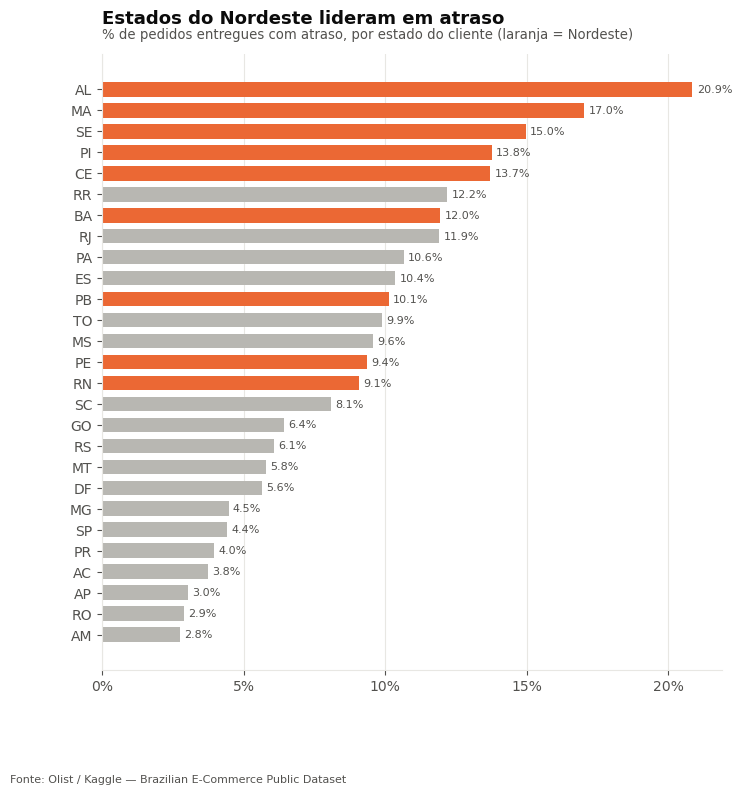

Nordeste x outras regiões:


,porcentagem_atrasados,nota_media
regiao_cliente,,
Nordeste,0.125,3.970
Outras regiões,0.060,4.175


In [3]:
por_estado = entregues.groupby("customer_state").agg(
    qtd_pedidos=("review_id", "count"),
    porcentagem_atrasados=("entrega_atrasada", "mean"),
    nota_media=("review_score", "mean"),
    dias_entrega_mediana=("dias_entrega", "median"),
    dias_prometidos_mediana=("dias_prometidos", "median"),
)
por_estado["porcentagem_atrasados"] *= 100
por_estado = por_estado.sort_values("porcentagem_atrasados")
display(por_estado.sort_values("porcentagem_atrasados", ascending=False).round(2))

fig, ax = plt.subplots(figsize=(8, 8))
cores = [LARANJA if uf in NORDESTE else CINZA for uf in por_estado.index]
barras = ax.barh(por_estado.index, por_estado["porcentagem_atrasados"], color=cores, height=0.7)
ax.bar_label(barras, labels=[f"{v:.1f}%" for v in por_estado["porcentagem_atrasados"]], padding=3,
             color=TEXTO_2, fontsize=8)
ax.set_title("Estados do Nordeste lideram em atraso", pad=22)
subtitulo(ax, "% de pedidos entregues com atraso, por estado do cliente (laranja = Nordeste)")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.xaxis.set_major_locator(mtick.MultipleLocator(5))
ax.grid(axis="y", visible=False)
fonte(fig)
salvar(fig, "07_atraso_por_estado")
plt.show()

print("Nordeste x outras regiões:")
display(entregues.groupby("regiao_cliente").agg(
    porcentagem_atrasados=("entrega_atrasada", "mean"), nota_media=("review_score", "mean")).round(3))

Detalhe interessante: estados do Norte como **AM, AP e RR** têm poucos atrasos, mas não porque a entrega é
rápida — o prazo prometido para eles já é muito longo (veja `dias_prometidos_mediana` na tabela).

## 3.3 Comprar de um vendedor do mesmo estado

In [4]:
entregues["mesmo_estado"] = (entregues["seller_state"] == entregues["customer_state"]).map(
    {True: "Mesmo estado", False: "Estados diferentes"})
mesmo_estado = entregues.groupby("mesmo_estado").agg(
    qtd_pedidos=("review_id", "count"),
    porcentagem_atrasados=("entrega_atrasada", "mean"),
    nota_media=("review_score", "mean"),
    dias_entrega_mediana=("dias_entrega", "median"),
)
mesmo_estado["porcentagem_atrasados"] *= 100
mesmo_estado.round(2)

,qtd_pedidos,porcentagem_atrasados,nota_media,dias_entrega_mediana
mesmo_estado,,,,
Estados diferentes,61707,7.89,4.09,12.0
Mesmo estado,34652,4.44,4.26,6.0


## 3.4 Onde o pedido trava: no vendedor ou na transportadora?

A entrega tem duas etapas:
1. **Vendedor**: da aprovação do pagamento até entregar o pacote à transportadora
2. **Transportadora**: da coleta até a casa do cliente

,dias_vendedor,dias_transportadora
entrega_atrasada,,
No prazo,1.8,6.9
Atrasado,3.1,26.1


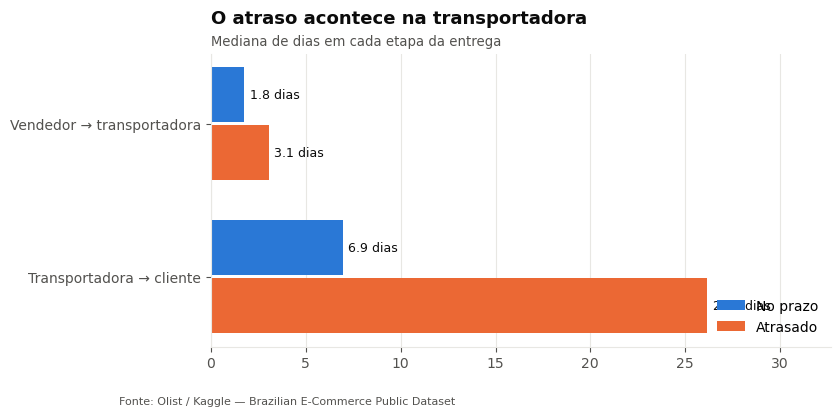

In [5]:
etapas = entregues.groupby("entrega_atrasada")[["dias_vendedor", "dias_transportadora"]].median()
etapas.index = etapas.index.map({False: "No prazo", True: "Atrasado"})
display(etapas.round(1))

fig, ax = plt.subplots(figsize=(8, 3.8))
nomes_etapas = ["Vendedor → transportadora", "Transportadora → cliente"]
y = range(len(nomes_etapas))
altura = 0.36
b1 = ax.barh([i - altura / 2 - 0.01 for i in y], etapas.loc["No prazo"], height=altura, color=AZUL, label="No prazo")
b2 = ax.barh([i + altura / 2 + 0.01 for i in y], etapas.loc["Atrasado"], height=altura, color=LARANJA, label="Atrasado")
for barras in (b1, b2):
    ax.bar_label(barras, labels=[f"{v:.1f} dias" for v in barras.datavalues], padding=4, color=TEXTO, fontsize=9)
ax.set_yticks(list(y), nomes_etapas)
ax.invert_yaxis()
ax.set_title("O atraso acontece na transportadora", pad=22)
subtitulo(ax, "Mediana de dias em cada etapa da entrega")
ax.set_xlim(0, etapas.values.max() * 1.25)
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
fonte(fig)
salvar(fig, "08_etapas_da_entrega")
plt.show()

## Conclusões do capítulo

- O atraso tem picos claros: **nov/2017** (Black Friday) e **fev–mar/2018**, quando passou de 14% e 18%.
  A nota média caiu nos mesmos meses.
- Clientes do **Nordeste** recebem com atraso muito mais vezes que os do Sul/Sudeste (AL ~21% contra SP ~4%).
- Quando vendedor e cliente estão no **mesmo estado**, a entrega leva metade do tempo e atrasa menos.
- Nos pedidos atrasados, o vendedor demora um pouco mais para despachar (3,1 contra 1,8 dias),
  mas o grande salto está na **transportadora** (26 contra 7 dias).